<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_haftal%C4%B1kg%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


1. kare alınıyor...


<IPython.core.display.Javascript object>

2. kare için biraz hareket et, alınıyor...


<IPython.core.display.Javascript object>

Hareketli piksel sayısı: 40334 | ROI: (0, 166, 296, 479)


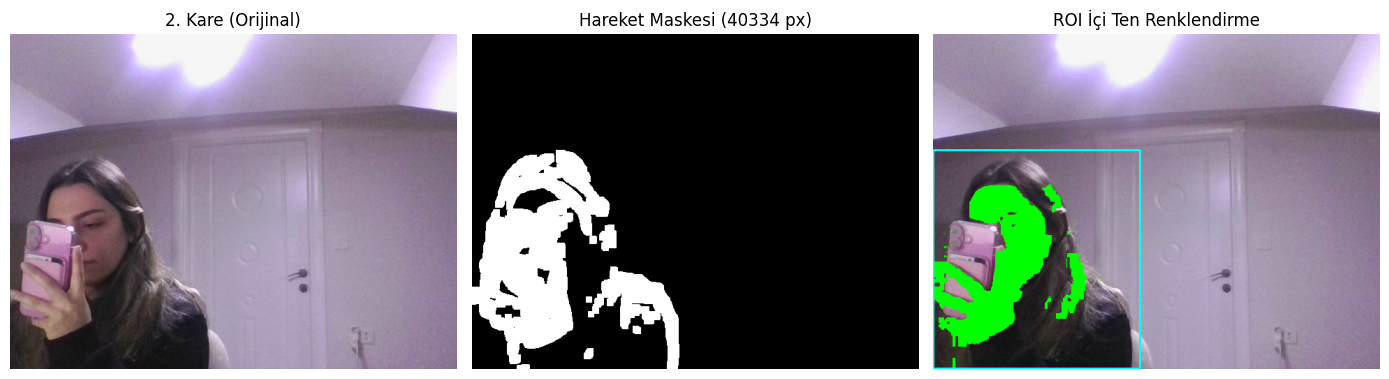

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def kamera_kFrame_al(quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            await new Promise((resolve) => setTimeout(resolve, 600));

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])
    arr = np.asarray(bytearray(binary), dtype=np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)

def roi_ten_tespit_ve_renklendir(frame1, frame2, min_moving_pixels=1500, diff_thresh=25):
    gray1 = cv2.GaussianBlur(cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    gray2 = cv2.GaussianBlur(cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY), (5, 5), 0)

    diff = cv2.absdiff(gray1, gray2)
    _, motion_mask = cv2.threshold(diff, diff_thresh, 255, cv2.THRESH_BINARY)
    motion_mask = cv2.dilate(motion_mask, np.ones((5, 5), np.uint8), iterations=2)

    moving_count = int(np.count_nonzero(motion_mask))
    output = frame2.copy()

    if moving_count < min_moving_pixels:
        return output, motion_mask, None, moving_count

    ys, xs = np.where(motion_mask > 0)
    x1, y1, x2, y2 = int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())
    roi = frame2[y1:y2 + 1, x1:x2 + 1]

    ycrcb_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2YCrCb)
    _, Cr, Cb = cv2.split(ycrcb_roi)
    skin_roi_mask = (Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127)

    colored_roi = roi.copy()
    colored_roi[skin_roi_mask] = [0, 255, 0]
    output[y1:y2 + 1, x1:x2 + 1] = colored_roi

    cv2.rectangle(output, (x1, y1), (x2, y2), (255, 255, 0), 2)
    return output, motion_mask, (x1, y1, x2, y2), moving_count

print("1. kare alınıyor...")
f1 = kamera_kFrame_al()
print("2. kare için biraz hareket et, alınıyor...")
f2 = kamera_kFrame_al()

res, mask, roi_box, mv_cnt = roi_ten_tespit_ve_renklendir(f1, f2, min_moving_pixels=1500)
print(f"Hareketli piksel sayısı: {mv_cnt} | ROI: {roi_box}")

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(f2, cv2.COLOR_BGR2RGB))
plt.title("2. Kare (Orijinal)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title(f"Hareket Maskesi ({mv_cnt} px)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
plt.title("ROI İçi Ten Renklendirme")
plt.axis("off")

plt.tight_layout()
plt.show()